Atividade Prática 01 – Aula 13

In [1]:
# Etapa 1
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

In [2]:
# Etapa 2
print(df.head())
df.info()
print(df.isna().sum())

df = df.drop_duplicates()

df["Sex"] = df["Sex"].str.strip().str.lower()
df["Sex"] = df["Sex"].replace({"male": "Masculino", "female": "Feminino"})

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print(df.isna().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [3]:
# Etapa 3
df_adultos = df[df["Age"] >= 18]
df_adultos.to_csv("titanic_adultos.csv", index=False)
print(len(df_adultos), "adultos salvos em titanic_adultos.csv")

778 adultos salvos em titanic_adultos.csv


Atividade Prática 02 – Aula 13

In [4]:
# Etapa 1
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("titanic_adultos.csv")
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name        Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris  Masculino  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Feminino  38.0      1   
2                             Heikkinen, Miss. Laina   Feminino  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Feminino  35.0      1   
4                           Allen, Mr. William Henry  Masculino  35.0      0   

   Parch            Ticket     Fare Embarked  
0      0         A/5 21171   7.2500        S  
1      0          PC 17599  71.2833        C  
2      0  STON/O2. 3101282   7.9250        S  
3      0            113803  53.1000        S  
4      0            373450   8.0500        S  


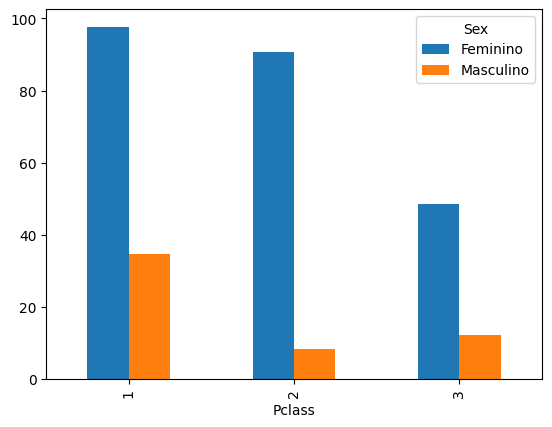

In [5]:
# Etapa 2
taxa = df.groupby(["Pclass", "Sex"])["Survived"].mean() * 100
taxa = taxa.unstack()
taxa.plot(kind="bar")
plt.show()

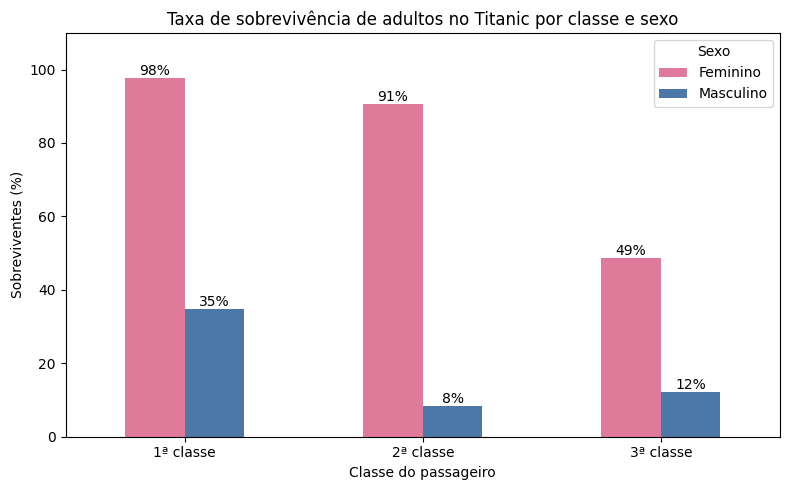

In [6]:
# Etapa 3
ax = taxa.plot(kind="bar", color=["#E07A9B", "#4C78A8"], figsize=(8, 5))
ax.set_title("Taxa de sobrevivência de adultos no Titanic por classe e sexo")
ax.set_xlabel("Classe do passageiro")
ax.set_ylabel("Sobreviventes (%)")
ax.set_xticklabels(["1ª classe", "2ª classe", "3ª classe"], rotation=0)
ax.set_ylim(0, 110)
ax.legend(title="Sexo")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%")
plt.tight_layout()
plt.show()